<div align="center">

# KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

## Eksekusi Prompt RTCIKOQV pada Lima Studi Kasus Geofisika
### Data Sintetis, Pengolahan, Visualisasi, dan Interpretasi

**Disusun oleh:**  
**SYAUQI ASADUL HAQ**  
**NIM: H061241052**  
**Kelas: B** 



### Struktur prompt RTCIKOQV

| Kode | Komponen | Fungsi |
|---|---|---|
| R | Role | Menentukan peran AI |
| T | Task | Menentukan tugas analisis |
| C | Context | Menjelaskan latar belakang masalah |
| I | Input | Menjelaskan data yang tersedia |
| K | Constraints | Menentukan batasan analisis |
| O | Output | Menentukan hasil yang diminta |
| Q | Quality Criteria | Menentukan kriteria hasil yang baik |
| V | Verification | Menentukan cara memeriksa hasil |

<a id="persiapan"></a>
# Persiapan — Import Library

Library yang digunakan untuk pengolahan array, tabel, perhitungan numerik sederhana, dan visualisasi. Seluruh studi kasus memakai model sintetis yang dibangun di dalam notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 110
})

print("Library berhasil diimpor.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Semua data dalam notebook ini bersifat SINTETIS.")

Library berhasil diimpor.
NumPy: 2.2.2
Pandas: 2.2.3
Semua data dalam notebook ini bersifat SINTETIS.


<a id="ert"></a>
# Studi Kasus 1 — Electrical Resistivity Tomography (ERT)
## Interpretasi Model Resistivitas 2D untuk Bidang Gelincir Longsor

### Deskripsi prompt RTCIKOQV

| Komponen | Isi prompt |
|---|---|
| **Role** | Pendamping geofisika untuk interpretasi awal hasil ERT. |
| **Task** | Menelaah distribusi resistivitas 2D dan mencari zona kontras yang mungkin berkaitan dengan bidang gelincir. |
| **Context** | Variasi litologi dan kandungan air dapat menghasilkan kontras resistivitas. |
| **Input** | Model resistivitas sintetis terhadap jarak dan kedalaman. |
| **Constraints** | Tidak menyimpulkan bidang gelincir hanya dari satu nilai resistivitas. |
| **Output** | Penampang, statistik, dan interpretasi zona anomali. |
| **Quality Criteria** | Interpretasi sesuai pola model dan membedakan observasi dari dugaan. |
| **Verification** | Pada survei nyata, periksa dengan geologi, topografi, kondisi air, dan data lapangan. |

### Eksekusi model sintetis

Model ini dibuat dengan tiga komponen sederhana: tanah penutup, material lebih resistif di bawahnya, dan zona resistivitas rendah yang melengkung sebagai **contoh hipotetis** zona kaya air. Bentuk ini hanya ilustrasi untuk mempraktikkan interpretasi.

,Parameter,Nilai,Satuan
0,Minimum,16.45,ohm.m
1,Maksimum,261.78,ohm.m
2,Rata-rata,200.17,ohm.m
3,Median,248.80,ohm.m


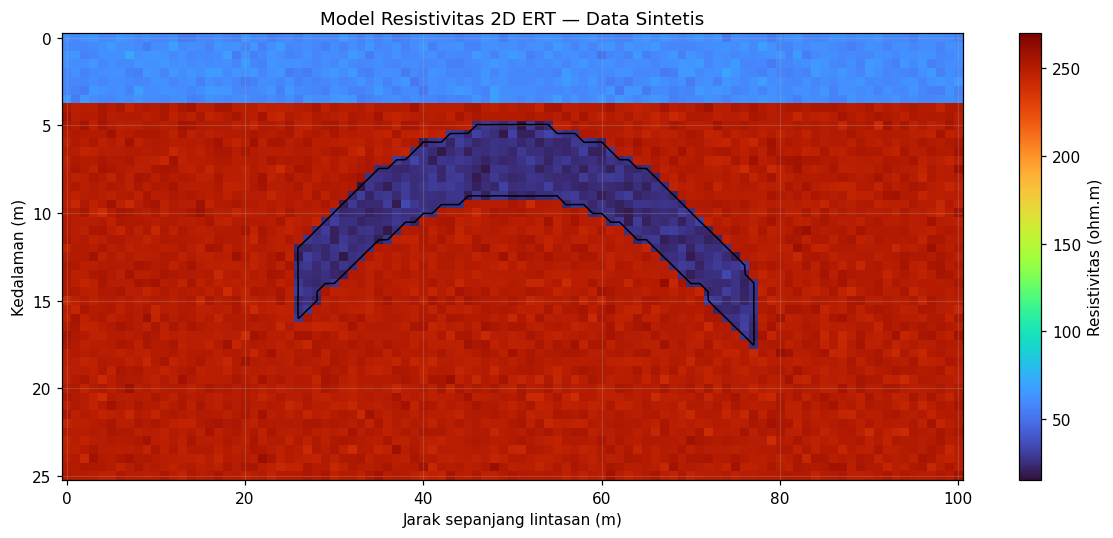

Persentase sel model dengan resistivitas < 40 ohm.m: 8.9%


In [2]:
# Grid model ERT
x_ert = np.linspace(0, 100, 101)        # jarak (m)
z_ert = np.linspace(0, 25, 51)         # kedalaman positif ke bawah (m)
X_ert, Z_ert = np.meshgrid(x_ert, z_ert)

rho_ert = np.where(Z_ert < 4, 60.0, 250.0)

# Zona resistivitas rendah melengkung: anomali sintetis, bukan bidang gelincir terverifikasi
z_lens = 7 + 0.12 * (X_ert - 50)**2 / 10
mask_low = (X_ert > 25) & (X_ert < 78) & (np.abs(Z_ert - z_lens) < 2.2)
rho_ert[mask_low] = 25.0

# Tambahkan variasi kecil yang terkontrol agar tampilan tidak terlalu homogen
noise = np.random.normal(0, 3, rho_ert.shape)
rho_ert = np.clip(rho_ert + noise, 5, None)

stats_ert = pd.DataFrame({
    "Parameter": ["Minimum", "Maksimum", "Rata-rata", "Median"],
    "Nilai": [
        rho_ert.min(), rho_ert.max(), rho_ert.mean(), np.median(rho_ert)
    ],
    "Satuan": ["ohm.m"] * 4
})
display(stats_ert.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.pcolormesh(X_ert, Z_ert, rho_ert, shading="auto", cmap="turbo",
                   vmin=15, vmax=270)
ax.invert_yaxis()
ax.set_xlabel("Jarak sepanjang lintasan (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Resistivitas 2D ERT — Data Sintetis")
cb = fig.colorbar(im, ax=ax)
cb.set_label("Resistivitas (ohm.m)")
ax.contour(X_ert, Z_ert, rho_ert, levels=[40], colors="black", linewidths=1)
plt.tight_layout()
plt.show()

low_fraction = np.mean(rho_ert < 40) * 100
print(f"Persentase sel model dengan resistivitas < 40 ohm.m: {low_fraction:.1f}%")

### Interpretasi awal ERT

- **Pengamatan model:** terdapat lapisan dangkal dengan resistivitas lebih rendah daripada material di bawahnya, serta zona resistivitas rendah yang melengkung pada bagian tengah model.
- **Interpretasi yang mungkin:** zona rendah dapat mewakili material lebih konduktif, misalnya material lebih jenuh air atau lempungan dalam skenario sintetis.
- **Batasan:** zona tersebut **belum membuktikan keberadaan bidang gelincir**. Pada data nyata, interpretasi perlu dibandingkan dengan bentuk lereng, geologi, muka air tanah, dan bukti lapangan.

### Pemeriksaan tambahan: profil resistivitas

Profil pada dua posisi memperlihatkan bagaimana resistivitas berubah terhadap kedalaman. Profil ini membantu membandingkan anomali dengan latar model, tetapi tetap bukan hasil pengukuran lapangan.


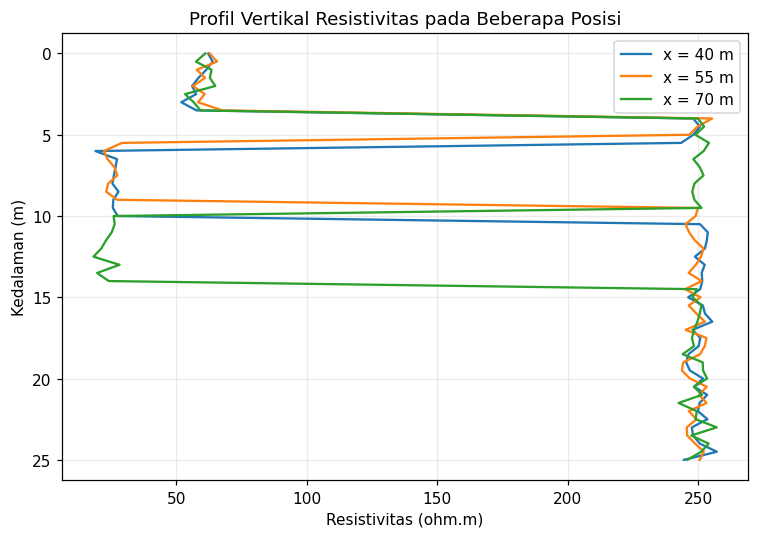

Jumlah sel model dengan resistivitas < 40 ohm.m: 459 dari 5151
Catatan: batas 40 ohm.m hanya ambang ilustratif untuk model ini, bukan kriteria universal bidang gelincir.


In [3]:
# Profil resistivitas pada dua posisi sepanjang lintasan
fig, ax = plt.subplots(figsize=(7, 5))
for x_pick in [40, 55, 70]:
    ix = np.argmin(np.abs(x_ert - x_pick))
    ax.plot(rho_ert[:, ix], z_ert, label=f"x = {x_ert[ix]:.0f} m")
ax.invert_yaxis()
ax.set_xlabel("Resistivitas (ohm.m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Profil Vertikal Resistivitas pada Beberapa Posisi")
ax.legend()
plt.tight_layout()
plt.show()

# Ringkasan sel dengan resistivitas rendah pada model
mask_low_summary = rho_ert < 40
print(f"Jumlah sel model dengan resistivitas < 40 ohm.m: {mask_low_summary.sum()} dari {rho_ert.size}")
print("Catatan: batas 40 ohm.m hanya ambang ilustratif untuk model ini, bukan kriteria universal bidang gelincir.")


<a id="ip"></a>
# Studi Kasus 2 — Induced Polarization (IP)
## Respons Chargeability dan Resistivitas untuk Indikasi Mineralisasi

### Deskripsi prompt RTCIKOQV

| Komponen | Isi prompt |
|---|---|
| **Role** | Pendamping geofisika untuk membaca respons IP. |
| **Task** | Membandingkan chargeability dan resistivitas untuk mengenali anomali yang perlu ditinjau. |
| **Context** | Chargeability menggambarkan respons polarisasi; interpretasi perlu mempertimbangkan resistivitas dan geologi. |
| **Input** | Model sintetis chargeability dan resistivitas 2D. |
| **Constraints** | Anomali IP tidak otomatis berarti bijih atau mineralisasi ekonomis. |
| **Output** | Dua penampang, tabel statistik, dan zona target hipotetis. |
| **Quality Criteria** | Kedua parameter dibahas bersama. |
| **Verification** | Survei nyata perlu dikonfirmasi dengan geologi, geokimia, alterasi, atau pemboran. |

### Eksekusi model sintetis

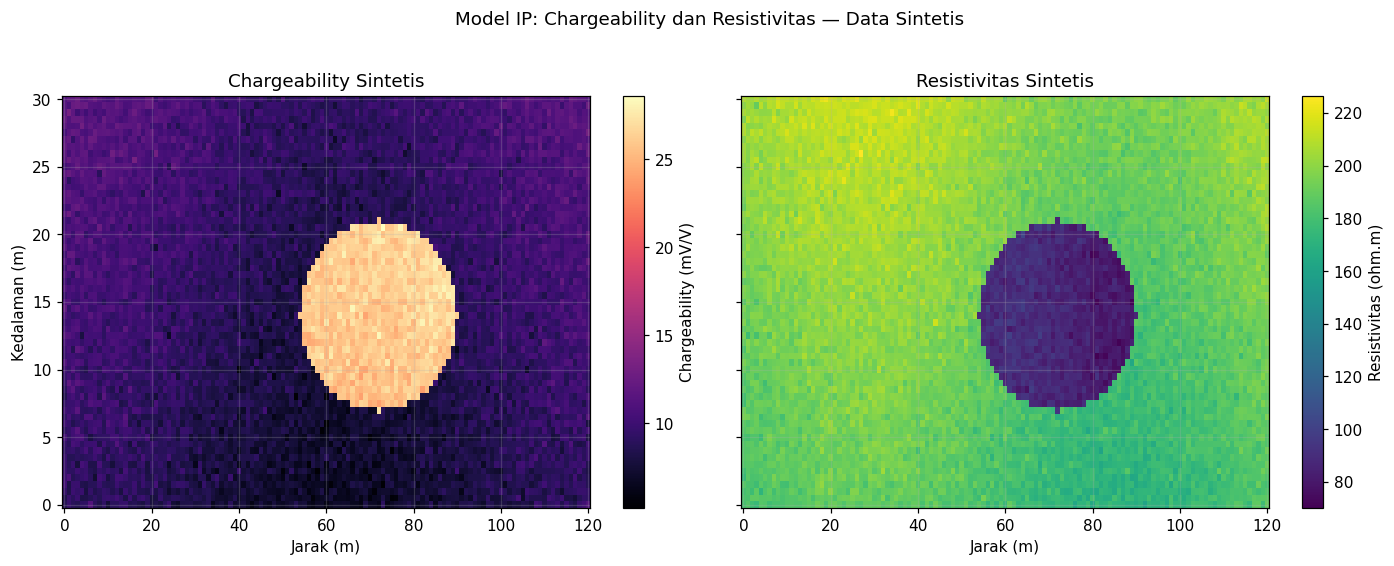

,Parameter,Nilai,Satuan
0,Chargeability minimum,5.15,mV/V
1,Chargeability maksimum,28.63,mV/V
2,Resistivitas minimum,70.03,ohm.m
3,Resistivitas maksimum,226.54,ohm.m


Jumlah sel pada zona anomali yang ditanam dalam model: 785


In [4]:
x_ip = np.linspace(0, 120, 121)
z_ip = np.linspace(0, 30, 61)
X_ip, Z_ip = np.meshgrid(x_ip, z_ip)

# Latar model
rho_ip = 180 + 0.8 * Z_ip + 10 * np.sin(X_ip / 18)
charge_ip = 8 + 0.08 * Z_ip + 1.2 * np.cos(X_ip / 20)

# Zona anomali sintetis, dipilih untuk demonstrasi saja
target_ip = ((X_ip - 72) / 18)**2 + ((Z_ip - 14) / 7)**2 <= 1
charge_ip[target_ip] += 18
rho_ip[target_ip] = 85 + 5 * np.sin(X_ip[target_ip] / 8)

charge_ip += np.random.normal(0, 0.7, charge_ip.shape)
rho_ip += np.random.normal(0, 4, rho_ip.shape)
charge_ip = np.clip(charge_ip, 0, None)
rho_ip = np.clip(rho_ip, 5, None)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
im0 = axes[0].pcolormesh(X_ip, Z_ip, charge_ip, shading="auto", cmap="magma")
axes[0].invert_yaxis()
axes[0].set_title("Chargeability Sintetis")
axes[0].set_xlabel("Jarak (m)")
axes[0].set_ylabel("Kedalaman (m)")
fig.colorbar(im0, ax=axes[0], label="Chargeability (mV/V)")

im1 = axes[1].pcolormesh(X_ip, Z_ip, rho_ip, shading="auto", cmap="viridis")
axes[1].invert_yaxis()
axes[1].set_title("Resistivitas Sintetis")
axes[1].set_xlabel("Jarak (m)")
fig.colorbar(im1, ax=axes[1], label="Resistivitas (ohm.m)")
fig.suptitle("Model IP: Chargeability dan Resistivitas — Data Sintetis", y=1.02)
plt.tight_layout()
plt.show()

ip_summary = pd.DataFrame({
    "Parameter": ["Chargeability minimum", "Chargeability maksimum",
                  "Resistivitas minimum", "Resistivitas maksimum"],
    "Nilai": [charge_ip.min(), charge_ip.max(), rho_ip.min(), rho_ip.max()],
    "Satuan": ["mV/V", "mV/V", "ohm.m", "ohm.m"]
})
display(ip_summary.round(2))

print("Jumlah sel pada zona anomali yang ditanam dalam model:", int(target_ip.sum()))

### Interpretasi awal IP

- **Pengamatan model:** zona anomali yang sengaja dibuat pada model memperlihatkan chargeability relatif lebih tinggi dan resistivitas lebih rendah daripada sebagian lingkungan sekitarnya.
- **Interpretasi yang mungkin:** kombinasi respons tersebut dapat menjadi zona yang menarik untuk dievaluasi lebih lanjut dalam konteks mineralisasi.
- **Batasan:** pola ini tidak cukup untuk memastikan keberadaan mineral tertentu, kadar, maupun nilai ekonomisnya. Interpretasi harus dikaitkan dengan geologi dan data pendukung.

### Pemeriksaan tambahan: perbandingan parameter IP

Scatter plot berikut membandingkan resistivitas dan chargeability untuk sel model yang ditandai sebagai target hipotetis dan sel latar. Pemisahan kelompok ini berasal dari cara data sintetis dibuat.


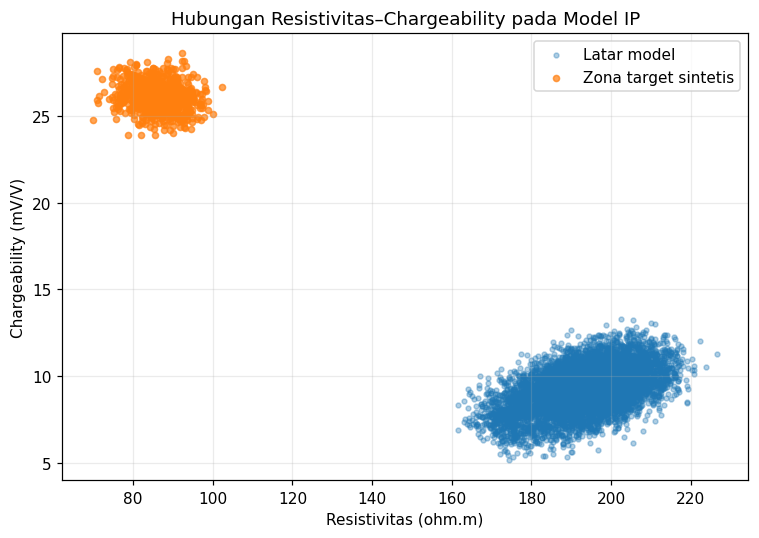

,Kelompok,Rata-rata chargeability (mV/V),Rata-rata resistivitas (ohm.m),Jumlah sel
0,Latar model,9.26,193.10,6596
1,Zona target sintetis,26.16,86.26,785


In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(rho_ip[~target_ip], charge_ip[~target_ip], s=10, alpha=0.35, label="Latar model")
ax.scatter(rho_ip[target_ip], charge_ip[target_ip], s=16, alpha=0.7, label="Zona target sintetis")
ax.set_xlabel("Resistivitas (ohm.m)")
ax.set_ylabel("Chargeability (mV/V)")
ax.set_title("Hubungan Resistivitas–Chargeability pada Model IP")
ax.legend()
plt.tight_layout()
plt.show()

ip_compare = pd.DataFrame({
    "Kelompok": ["Latar model", "Zona target sintetis"],
    "Rata-rata chargeability (mV/V)": [charge_ip[~target_ip].mean(), charge_ip[target_ip].mean()],
    "Rata-rata resistivitas (ohm.m)": [rho_ip[~target_ip].mean(), rho_ip[target_ip].mean()],
    "Jumlah sel": [(~target_ip).sum(), target_ip.sum()]
})
display(ip_compare.round(2))


<a id="refraksi"></a>
# Studi Kasus 3 — Seismik Refraksi
## Kurva Travel Time dan Model Kecepatan Berlapis

### Deskripsi prompt RTCIKOQV

| Komponen | Isi prompt |
|---|---|
| **Role** | Pendamping interpretasi seismik refraksi. |
| **Task** | Membaca kurva waktu tempuh dan memperkirakan model dua lapisan sederhana. |
| **Context** | Kecepatan gelombang dapat berbeda antar material bawah permukaan. |
| **Input** | Jarak geofon dan waktu tiba sintetis. |
| **Constraints** | Model sederhana tidak mewakili semua kondisi geologi; kecepatan saja tidak memastikan jenis batuan. |
| **Output** | Kurva travel time, estimasi kecepatan, dan tabel ringkasan. |
| **Quality Criteria** | Parameter diperoleh dari model kurva yang jelas. |
| **Verification** | Data nyata perlu diuji terhadap pick waktu tiba, geometri akuisisi, dan kondisi geologi. |

### Eksekusi model dua lapisan

Kurva dibangun menggunakan waktu tiba gelombang langsung dan gelombang refraksi kritis. Parameter yang dipakai adalah kecepatan lapisan atas \(v_1\), kecepatan lapisan bawah \(v_2\), dan ketebalan lapisan atas \(h\).

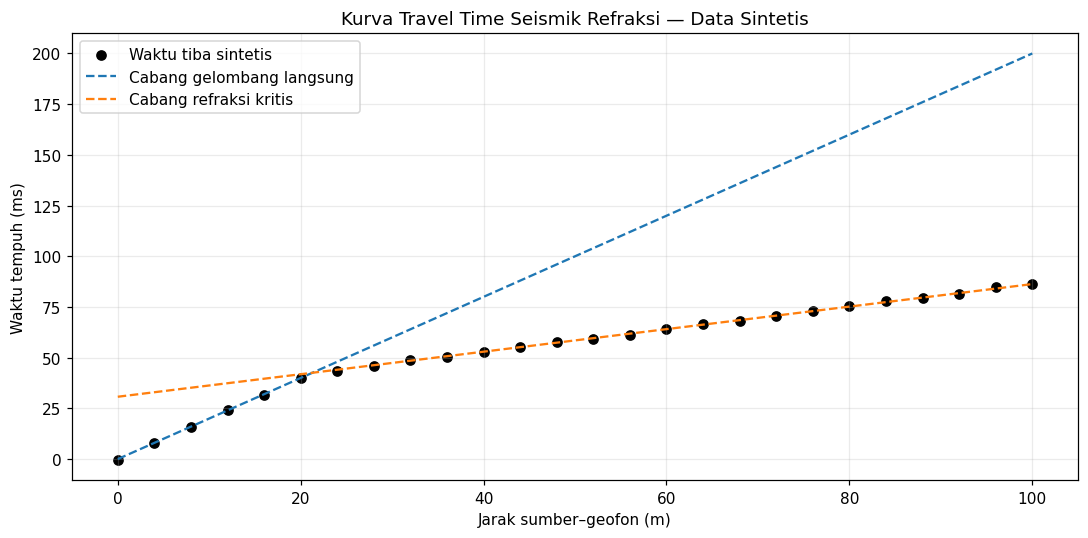

,Parameter,Nilai,Satuan
0,Kecepatan lapisan 1 (model),500.00,m/s
1,Kecepatan lapisan 2 (model),1800.00,m/s
2,Ketebalan lapisan 1 (model),8.00,m
3,Estimasi kecepatan dari slope awal,486.87,m/s
4,Estimasi kecepatan dari slope akhir,1786.16,m/s
5,Estimasi ketebalan dari intercept time,7.69,m


In [6]:
v1_true = 500.0   # m/s, nilai model sintetis
v2_true = 1800.0  # m/s, nilai model sintetis
h_true = 8.0      # m, ketebalan lapisan atas
x_ref = np.linspace(0, 100, 26)

# Waktu gelombang langsung
t_direct = x_ref / v1_true

# Waktu refraksi kritis untuk model dua lapisan dengan v2 > v1
sin_ic = v1_true / v2_true
cos_ic = np.sqrt(1 - sin_ic**2)
t_intercept = 2 * h_true * cos_ic / v1_true
t_head = t_intercept + x_ref / v2_true

# Waktu tiba pertama merupakan minimum dari dua cabang
t_first = np.minimum(t_direct, t_head)
t_observed = t_first + np.random.normal(0, 0.0003, len(x_ref))

# Fit garis pada bagian awal dan akhir sebagai ilustrasi estimasi kecepatan
early = x_ref <= 15
late = x_ref >= 55
slope_early, intercept_early = np.polyfit(x_ref[early], t_observed[early], 1)
slope_late, intercept_late = np.polyfit(x_ref[late], t_observed[late], 1)
v1_est = 1 / slope_early
v2_est = 1 / slope_late
# Estimasi ketebalan dari intercept time hasil fit cabang refraksi
h_est = max(0.0, intercept_late * v1_est / (2 * np.sqrt(1 - (v1_est / v2_est)**2))) if v2_est > v1_est else np.nan

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(x_ref, t_observed * 1000, label="Waktu tiba sintetis", color="black")
ax.plot(x_ref, t_direct * 1000, "--", label="Cabang gelombang langsung")
ax.plot(x_ref, t_head * 1000, "--", label="Cabang refraksi kritis")
ax.set_xlabel("Jarak sumber–geofon (m)")
ax.set_ylabel("Waktu tempuh (ms)")
ax.set_title("Kurva Travel Time Seismik Refraksi — Data Sintetis")
ax.legend()
plt.tight_layout()
plt.show()

refraction_summary = pd.DataFrame({
    "Parameter": ["Kecepatan lapisan 1 (model)", "Kecepatan lapisan 2 (model)",
                  "Ketebalan lapisan 1 (model)",
                  "Estimasi kecepatan dari slope awal",
                  "Estimasi kecepatan dari slope akhir",
                  "Estimasi ketebalan dari intercept time"],
    "Nilai": [v1_true, v2_true, h_true, v1_est, v2_est, h_est],
    "Satuan": ["m/s", "m/s", "m", "m/s", "m/s", "m"]
})
display(refraction_summary.round(2))

### Visualisasi model lapisan

Penampang berikut memperlihatkan geometri model yang dipakai untuk membuat kurva, bukan hasil inversi dari data lapangan.

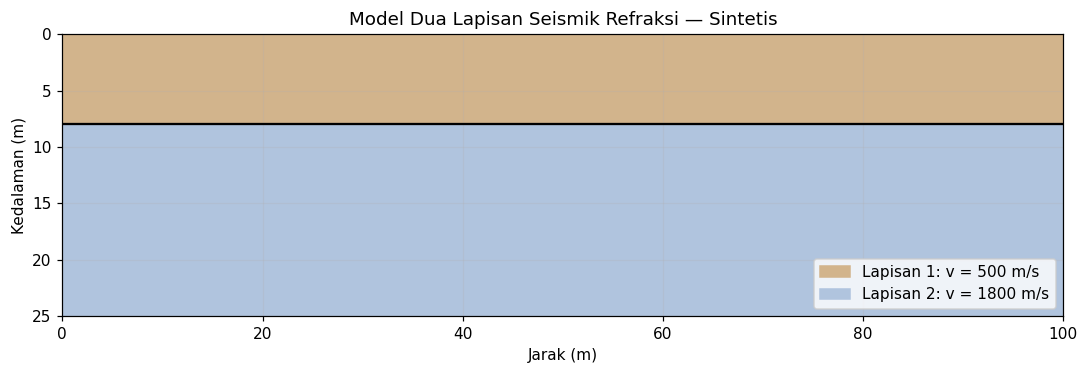

Interpretasi model: kecepatan lapisan bawah lebih tinggi daripada lapisan atas.
Ketebalan lapisan atas yang ditanam dalam model: 8.0 m.
Nilai ini adalah parameter model sintetis, bukan hasil survei lapangan.


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between([0, 100], [0, 0], [h_true, h_true], color="tan",
                label=f"Lapisan 1: v = {v1_true:.0f} m/s")
ax.fill_between([0, 100], [h_true, h_true], [25, 25], color="lightsteelblue",
                label=f"Lapisan 2: v = {v2_true:.0f} m/s")
ax.axhline(h_true, color="black", linewidth=1.5)
ax.set_xlim(0, 100)
ax.set_ylim(25, 0)
ax.set_xlabel("Jarak (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Dua Lapisan Seismik Refraksi — Sintetis")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Interpretasi model: kecepatan lapisan bawah lebih tinggi daripada lapisan atas.")
print("Ketebalan lapisan atas yang ditanam dalam model:", h_true, "m.")
print("Nilai ini adalah parameter model sintetis, bukan hasil survei lapangan.")

### Interpretasi awal seismik refraksi

- **Pengamatan model:** kurva memperlihatkan dua cabang waktu tempuh dengan kemiringan berbeda.
- **Makna fisik:** kemiringan kurva waktu–jarak berkaitan dengan kebalikan kecepatan rambat. Cabang dengan kemiringan lebih kecil menunjukkan kecepatan lebih tinggi.
- **Batasan:** ketebalan lapisan dan kecepatan yang ditampilkan berasal dari model sintetis. Data nyata memerlukan pemeriksaan kualitas pick, geometri, asumsi lapisan, serta kemungkinan variasi lateral.

### Pemeriksaan tambahan: estimasi model

Kecepatan dihitung dari kebalikan kemiringan cabang travel time. Ketebalan lapisan atas dapat diperkirakan dari intercept time dengan asumsi model dua lapisan horizontal dan kecepatan lapisan kedua lebih tinggi.


In [8]:
print(f"Kecepatan lapisan atas model       : {v1_true:.1f} m/s")
print(f"Estimasi dari cabang awal          : {v1_est:.1f} m/s")
print(f"Kecepatan lapisan bawah model      : {v2_true:.1f} m/s")
print(f"Estimasi dari cabang akhir         : {v2_est:.1f} m/s")
print(f"Ketebalan lapisan atas model       : {h_true:.2f} m")
print(f"Estimasi ketebalan dari intercept  : {h_est:.2f} m")
print("Nilai estimasi dapat berbeda dari parameter model karena noise sintetis dan pendekatan fit linear.")


Kecepatan lapisan atas model       : 500.0 m/s
Estimasi dari cabang awal          : 486.9 m/s
Kecepatan lapisan bawah model      : 1800.0 m/s
Estimasi dari cabang akhir         : 1786.2 m/s
Ketebalan lapisan atas model       : 8.00 m
Estimasi ketebalan dari intercept  : 7.69 m
Nilai estimasi dapat berbeda dari parameter model karena noise sintetis dan pendekatan fit linear.


<a id="mt"></a>
# Studi Kasus 4 — Magnetotellurik (MT)
## Model Resistivitas terhadap Kedalaman untuk Sistem Panas Bumi

### Deskripsi prompt RTCIKOQV

| Komponen | Isi prompt |
|---|---|
| **Role** | Pendamping interpretasi model resistivitas MT. |
| **Task** | Menelaah zona konduktif dan resistif dalam model berlapis. |
| **Context** | Resistivitas dipengaruhi litologi, fluida, temperatur, porositas, dan alterasi. |
| **Input** | Model resistivitas 1D sintetis terhadap kedalaman. |
| **Constraints** | Zona konduktif tidak otomatis merupakan reservoir; nilai resistivitas bukan identifikasi litologi tunggal. |
| **Output** | Grafik resistivitas dan tabel lapisan model. |
| **Quality Criteria** | Interpretasi membedakan nilai model dari dugaan geologi. |
| **Verification** | Periksa terhadap geologi, struktur, geokimia, manifestasi, dan data sumur bila tersedia. |

### Eksekusi model sintetis

Untuk latihan ini, dibuat tiga lapisan dengan resistivitas berbeda. Model tersebut hanya menunjukkan cara menampilkan dan membaca kontras resistivitas.

,Lapisan,Kedalaman atas (m),Kedalaman bawah (m),Resistivitas (ohm.m),Deskripsi model
0,Lapisan 1,0,500,80,Relatif resistif
1,Lapisan 2,500,1500,8,Konduktif
2,Lapisan 3,1500,3000,45,Lebih resistif


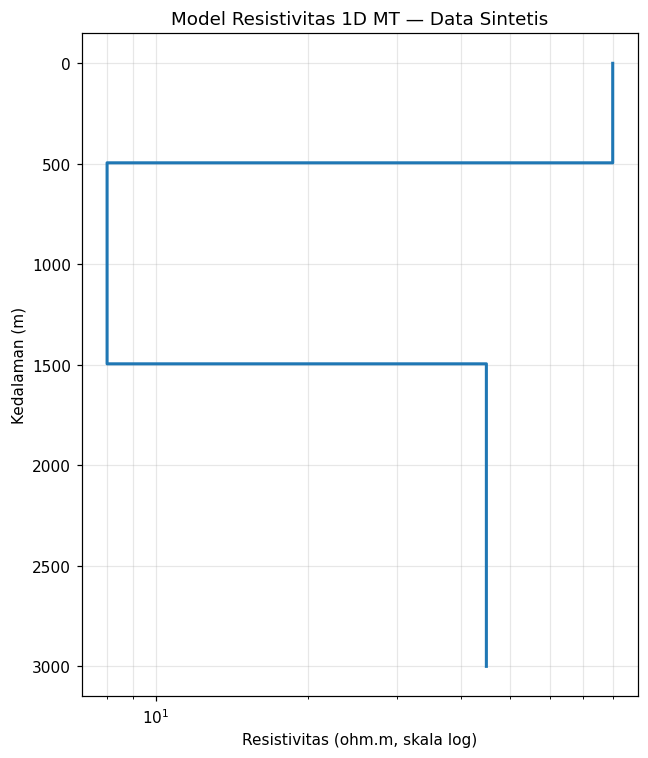

Rentang resistivitas model: 8.0–80.0 ohm.m


In [9]:
layers_mt = pd.DataFrame({
    "Lapisan": ["Lapisan 1", "Lapisan 2", "Lapisan 3"],
    "Kedalaman atas (m)": [0, 500, 1500],
    "Kedalaman bawah (m)": [500, 1500, 3000],
    "Resistivitas (ohm.m)": [80, 8, 45],
    "Deskripsi model": ["Relatif resistif", "Konduktif", "Lebih resistif"]
})
display(layers_mt)

depth_mt = np.linspace(0, 3000, 601)
rho_mt = np.select(
    [depth_mt < 500, (depth_mt >= 500) & (depth_mt < 1500)],
    [80, 8],
    default=45
)

fig, ax = plt.subplots(figsize=(6, 7))
ax.step(rho_mt, depth_mt, where="post", linewidth=2)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("Resistivitas (ohm.m, skala log)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Resistivitas 1D MT — Data Sintetis")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print("Rentang resistivitas model:", f"{rho_mt.min():.1f}–{rho_mt.max():.1f} ohm.m")

### Interpretasi awal MT

- **Pengamatan model:** lapisan kedua mempunyai resistivitas paling rendah, diapit oleh lapisan yang lebih resistif.
- **Interpretasi yang mungkin:** dalam konteks panas bumi, zona konduktif dapat berkaitan dengan lempung alterasi atau fluida, tetapi penyebabnya tidak tunggal.
- **Batasan:** model ini tidak menggunakan data impedansi MT, fase, atau proses inversi. Karena itu, lapisan konduktif di sini hanya contoh model, bukan bukti keberadaan cap rock atau reservoir.

### Pemeriksaan tambahan: kontras antarlapisan

Perbandingan logaritmik berikut menonjolkan perbedaan resistivitas antarlapisan. Karena resistivitas memiliki rentang nilai lebar, skala log lebih sesuai untuk visualisasi.


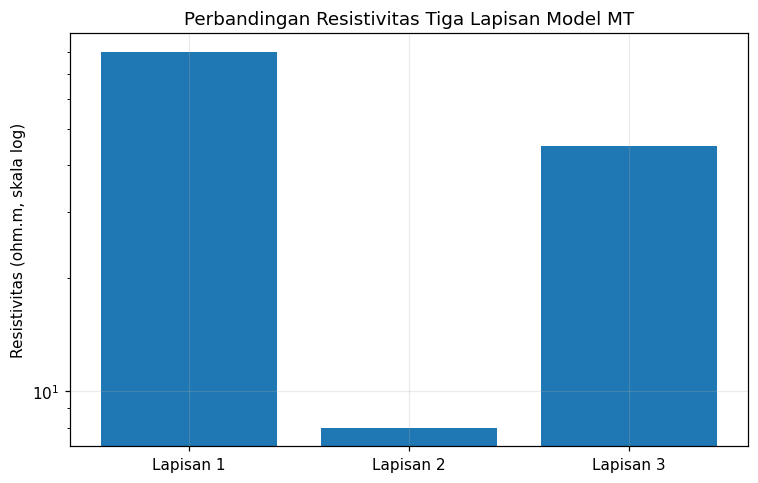

,Perbandingan,Rasio resistivitas
0,Lapisan 1 terhadap 2,10.00
1,Lapisan 3 terhadap 2,5.62


Rasio menunjukkan kontras pada model; bukan klasifikasi litologi otomatis.


In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(layers_mt["Lapisan"], layers_mt["Resistivitas (ohm.m)"])
ax.set_yscale("log")
ax.set_ylabel("Resistivitas (ohm.m, skala log)")
ax.set_title("Perbandingan Resistivitas Tiga Lapisan Model MT")
plt.tight_layout()
plt.show()

rho_values = layers_mt["Resistivitas (ohm.m)"].to_numpy()
contrast = pd.DataFrame({
    "Perbandingan": ["Lapisan 1 terhadap 2", "Lapisan 3 terhadap 2"],
    "Rasio resistivitas": [rho_values[0]/rho_values[1], rho_values[2]/rho_values[1]]
})
display(contrast.round(2))
print("Rasio menunjukkan kontras pada model; bukan klasifikasi litologi otomatis.")


<a id="gravitasi"></a>
# Studi Kasus 5 — Gravitasi
## Anomali Gravitasi untuk Indikasi Kontras Densitas

### Deskripsi prompt RTCIKOQV

| Komponen | Isi prompt |
|---|---|
| **Role** | Pendamping interpretasi pola anomali gravitasi. |
| **Task** | Menelaah anomali tinggi dan rendah sebagai indikasi awal kontras densitas. |
| **Context** | Perbedaan densitas dan geometri sumber bawah permukaan memengaruhi medan gravitasi. |
| **Input** | Profil anomali gravitasi sintetis terhadap jarak. |
| **Constraints** | Anomali positif atau negatif tidak cukup untuk menetapkan jenis batuan atau struktur secara pasti. |
| **Output** | Grafik profil, statistik, dan interpretasi pola. |
| **Quality Criteria** | Interpretasi mempertimbangkan bentuk anomali dan ketidakunikan sumber. |
| **Verification** | Pada data nyata, bandingkan dengan geologi, topografi, densitas batuan, dan metode geofisika lain. |

### Eksekusi profil anomali sintetis

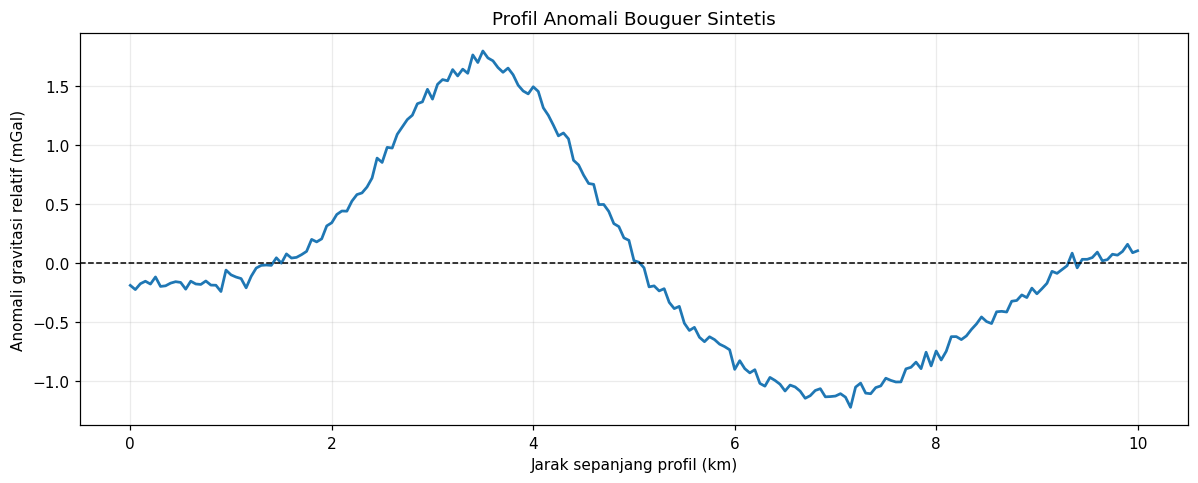

,Parameter,Nilai (mGal)
0,Minimum,-1.221
1,Maksimum,1.795
2,Rata-rata,0.019
3,Simpangan baku,0.829


Anomali tertinggi pada jarak 3.50 km: 1.795 mGal
Anomali terendah pada jarak 7.15 km: -1.221 mGal


In [11]:
x_g = np.linspace(0, 10000, 201)  # meter

# Dua komponen anomali hipotetis untuk membentuk profil kompleks
anomali_positif = 1.8 * np.exp(-0.5 * ((x_g - 3500) / 900)**2)
anomali_negatif = -1.2 * np.exp(-0.5 * ((x_g - 7000) / 1300)**2)
regional = 0.00004 * (x_g - 5000)
noise_g = np.random.normal(0, 0.04, len(x_g))
bouguer = anomali_positif + anomali_negatif + regional + noise_g

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x_g / 1000, bouguer, linewidth=1.8)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("Jarak sepanjang profil (km)")
ax.set_ylabel("Anomali gravitasi relatif (mGal)")
ax.set_title("Profil Anomali Bouguer Sintetis")
plt.tight_layout()
plt.show()

gravity_summary = pd.DataFrame({
    "Parameter": ["Minimum", "Maksimum", "Rata-rata", "Simpangan baku"],
    "Nilai (mGal)": [bouguer.min(), bouguer.max(), bouguer.mean(), bouguer.std()]
})
display(gravity_summary.round(3))

imax = np.argmax(bouguer)
imin = np.argmin(bouguer)
print(f"Anomali tertinggi pada jarak {x_g[imax]/1000:.2f} km: {bouguer[imax]:.3f} mGal")
print(f"Anomali terendah pada jarak {x_g[imin]/1000:.2f} km: {bouguer[imin]:.3f} mGal")

### Interpretasi awal gravitasi

- **Pengamatan model:** profil memperlihatkan satu anomali relatif tinggi dan satu anomali relatif rendah di atas tren regional.
- **Interpretasi yang mungkin:** pola ini dapat mencerminkan kontras densitas bawah permukaan dalam skenario sederhana yang digunakan untuk membangun data.
- **Batasan:** anomali gravitasi bersifat tidak unik. Bentuk yang mirip dapat dihasilkan oleh sumber dengan geometri, kedalaman, atau kontras densitas berbeda. Interpretasi geologi tidak dapat dipastikan dari profil ini saja.

### Pemeriksaan tambahan: komponen pembentuk anomali

Grafik berikut memisahkan dua komponen anomali hipotetis dan tren regional yang digunakan untuk membentuk profil. Ini memperlihatkan bahwa pola total merupakan gabungan beberapa komponen, sehingga interpretasi anomali gravitasi bersifat tidak unik.


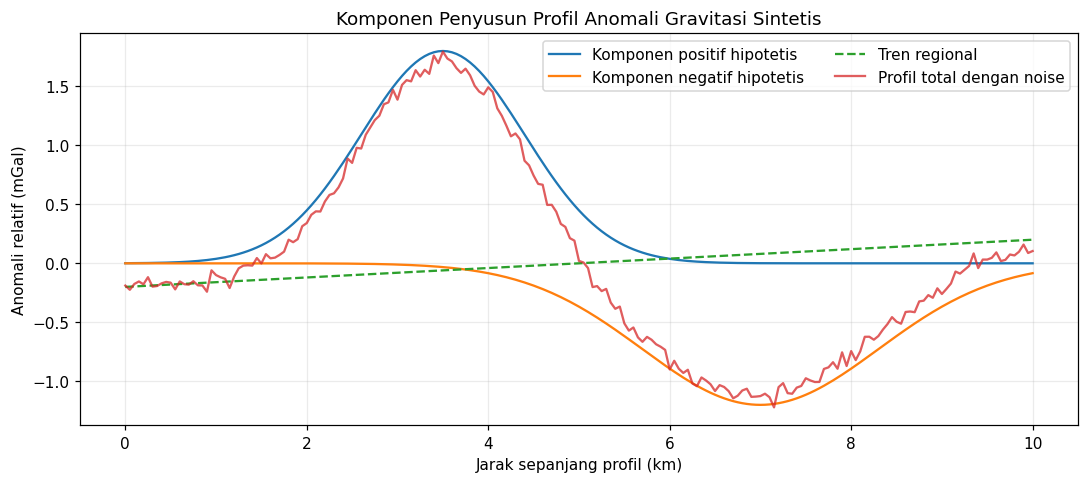

Puncak dan lembah profil total dipengaruhi gabungan komponen sumber, tren regional, dan noise.


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x_g/1000, anomali_positif, label="Komponen positif hipotetis")
ax.plot(x_g/1000, anomali_negatif, label="Komponen negatif hipotetis")
ax.plot(x_g/1000, regional, label="Tren regional", linestyle="--")
ax.plot(x_g/1000, bouguer, label="Profil total dengan noise", alpha=0.75)
ax.set_xlabel("Jarak sepanjang profil (km)")
ax.set_ylabel("Anomali relatif (mGal)")
ax.set_title("Komponen Penyusun Profil Anomali Gravitasi Sintetis")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

print("Puncak dan lembah profil total dipengaruhi gabungan komponen sumber, tren regional, dan noise.")


## Perbandingan keluaran lima studi kasus

Tabel ini merangkum jenis data yang dimodelkan dan keluaran yang perlu diperiksa pada tiap metode. Karena semua data pada notebook ini sintetis, tabel bukan hasil survei geofisika lapangan.


In [13]:
comparison = pd.DataFrame({
    "Metode": ["ERT", "IP", "Seismik refraksi", "MT", "Gravitasi"],
    "Parameter utama": ["Resistivitas", "Chargeability dan resistivitas", "Waktu tempuh dan kecepatan", "Resistivitas terhadap kedalaman", "Anomali gravitasi"],
    "Keluaran utama": ["Penampang 2D", "Dua penampang + scatter", "Kurva T-X + model lapisan", "Model 1D berlapis", "Profil anomali dan komponennya"],
    "Batasan utama": ["Zona konduktif bukan bukti slip surface", "Anomali bukan bukti bijih ekonomis", "Model 2 lapisan menyederhanakan geologi", "Tanpa data impedansi/inversi", "Sumber anomali tidak unik"]
})
display(comparison)


,Metode,Parameter utama,Keluaran utama,Batasan utama
0,ERT,Resistivitas,Penampang 2D,Zona konduktif bukan bukti slip surface
1,IP,Chargeability dan resistivitas,Dua penampang + scatter,Anomali bukan bukti bijih ekonomis
2,Seismik refraksi,Waktu tempuh dan kecepatan,Kurva T-X + model lapisan,Model 2 lapisan menyederhanakan geologi
3,MT,Resistivitas terhadap kedalaman,Model 1D berlapis,Tanpa data impedansi/inversi
4,Gravitasi,Anomali gravitasi,Profil anomali dan komponennya,Sumber anomali tidak unik


<a id="ringkasan"></a>
# Ringkasan Hasil dan Batasan

| Metode | Hasil yang ditampilkan | Hal yang tidak boleh disimpulkan langsung |
|---|---|---|
| ERT | Penampang resistivitas 2D dan zona resistivitas rendah | Zona rendah pasti merupakan bidang gelincir |
| IP | Penampang chargeability dan resistivitas | Anomali IP pasti merupakan bijih ekonomis |
| Seismik refraksi | Kurva travel time dan model dua lapisan | Kecepatan tertentu pasti menunjukkan satu jenis batuan |
| MT | Model resistivitas 1D terhadap kedalaman | Zona konduktif pasti reservoir panas bumi |
| Gravitasi | Profil anomali relatif tinggi dan rendah | Anomali positif/negatif secara tunggal menentukan litologi |

## Kesimpulan

Notebook ini memperlihatkan bagaimana prompt RTCIKOQV dapat diterjemahkan menjadi alur kerja komputasi: mendefinisikan masalah, membangun atau memasukkan data, melakukan perhitungan, membuat visualisasi, lalu menulis interpretasi dengan batasan yang jelas.

**Seluruh angka dan grafik di notebook ini berasal dari data/model sintetis.** Untuk analisis lapangan, data asli, metadata akuisisi, informasi geologi, dan proses pengolahan yang sesuai harus digunakan. Interpretasi yang dibuat di sini adalah demonstrasi awal dan bukan pengganti inversi atau validasi geologi.